In [41]:
%matplotlib inline
%precision 16
import numpy
import matplotlib.pyplot as plt
import scipy.linalg as sl
import math
import scipy.sparse as sparse
import scipy.linalg
import scipy.sparse.linalg as linalg

from tqdm import tqdm

Before you turn this problem in, make sure everything runs as expected. First, restart the kernel (in the menubar, select Kernel $\rightarrow$ Restart) and then run all cells (in the menubar, select Cell $\rightarrow$ Run All).

Make sure you fill in any place that says YOUR CODE HERE or "YOUR ANSWER HERE", as well as your name and collaborators below:

# HW 5: Parabolic Problems

# Question 1 - Parabolic + Periodic BCs

Consider the temperature distribution in a thin circular ring with perimeter $2L$. Assume that the lateral surfaces are perfectly insulated, such that the temperature is distributed evenly throughout the ring cross-section and that the ends at $x=-L$ and $x=L$ are in perfect thermal contact.

This mathematical problem can be formulated as a heat equation with factor $k \in \mathbb R$ and periodic boundary conditions.
$$
    \frac{\partial u}{\partial t} = k \ \frac{\partial^2 u}{\partial x^2} \qquad \text{ on } [-L,L]\times \mathbb R_+\\
    u(x,0) = u_0(x) ~~~~~~ u(-L,t) = u(L,t) ~~~~~ \frac{\partial}{\partial x} u(-L,t) = \frac{\partial}{\partial x} u(L,t).
$$

**(a)** [10] Solve the problem analytically.

We're going to use the method of seperation of variables. Consider $u(x,t)=T(t)X(x)$, then 

$$
    \dfrac{1}{k}\dfrac{T'(t)}{T(t)} = \dfrac{X''(x)}{X(x)} = -\lambda\qquad \Rightarrow\qquad X(x) = c_1\cos\sqrt\lambda x+c_2\sin\sqrt\lambda x
$$

By the period condition, the period of $u$ over space should be $2L$, hence $\sqrt{\lambda}=\dfrac{n\pi}{L}$, $\lambda_n=\left(\dfrac{n\pi}{L}\right)^2$, thus

$$
    X(x) = c_1\cos\dfrac{n\pi x}{L}+c_2\sin\dfrac{n\pi x}{L},\quad T(t)=\exp\left(-k\left(\dfrac{n\pi}{L}\right)^2t\right)
$$

Hence $u_n(x,t)=X_n(x)T_n(t)=\exp\left(-k\left(\dfrac{n\pi}{L}\right)^2t\right)(a_n\cos\dfrac{n\pi x}{L}+b_n\sin\dfrac{n\pi x}{L})$. Since

$$
    u(x,t)=\sum_{n=0}^{+\infty} u_n(x,t),\quad u(x,0)=\sum(a_n\cos\dfrac{n\pi x}{L}+b_n\sin\dfrac{n\pi x}{L})=u_0(x)
$$ 

which is the Fourier expansion of $u_0(x)$, therefore

$$
    a_n=\dfrac{1}{L}\int_{-L}^{L}u_0(x)\cos\dfrac{n\pi x}{L},\quad b_n=\dfrac{1}{L}\int_{-L}^{L}u_0(x)\sin\dfrac{n\pi x}{L}
$$

and

$$
    \begin{align}
    u(x,t)&=\sum_{n=0}^{+\infty}\exp\left(-k\left(\dfrac{n\pi}{L}\right)^2t\right)(\dfrac{1}{L}\int_{-L}^{L}u_0(s)\cos\dfrac{n\pi s}{L}\cos\dfrac{n\pi x}{L}ds+\dfrac{1}{L}\int_{-L}^{L}u_0(s)\sin\dfrac{n\pi s}{L}\sin\dfrac{n\pi x}{L}ds)\\
    &=\sum_{n=0}^{+\infty}\dfrac{1}{L}\exp\left(-k\left(\dfrac{n\pi}{L}\right)^2t\right)\left(\int_{-L}^{L}u_0(s)\cos\dfrac{n\pi (s-x)}{L}ds\right)
    \end{align}

**(b)** [15] Write down the discretization for the problem resulting from using the Crank-Nicholson method showing the full matrix representation of the discretization and how you came to that representation.  Note that the periodicity will cause there to be a dependence that "wraps around" the domain so that the left most point in the domain depends on the right most point and vice-versa.

**Answer** Differentiate both time and space, we have

$$
    \dfrac{T_i^{n+1}-T_i^n}{\Delta t} = \dfrac{1}{2}\left(\kappa\dfrac{T_{i+1}^n-2T_i^n+T_{i-1}^n}{\Delta x^2}+\kappa\dfrac{T_{i+1}^{n+1}-2T_i^{n+1}+T_{i-1}^{n+1}}{\Delta x^2}\right)
$$

Separating terms, we have

$$
    2(1+\sigma)T_i^{n+1}-\sigma T_{i+1}^{n+1}-\sigma T_{i-1}^{n+1}= \sigma T_{i+1}^n+2(1-\sigma)T_i^n+\sigma T_{i-1}^n,\quad \sigma=\dfrac{\kappa\Delta t}{\Delta x^2}
$$

Making using of $T_{0} = T_n$ (periodity), hence we have

$$
    \begin{align}
    &&&\begin{bmatrix}
    2(1+\sigma)&-\sigma&0&0&\cdots&0&-\sigma\\
    -\sigma&2(1+\sigma)&-\sigma&0&\cdots&0&0\\
    0&-\sigma&2(1+\sigma)&-\sigma&\cdots&0&0\\
    0&0&-\sigma&2(1+\sigma)&\cdots&0&0\\
    \vdots&\vdots&\vdots&\vdots&\ddots&\vdots&\vdots\\
    0&0&0&0&\cdots&2(1+\sigma)&-\sigma\\
    -\sigma&0&0&0&\cdots&-\sigma&2(1+\sigma)
    \end{bmatrix}
    \begin{bmatrix}
    T_1^{n+1}\\T_2^{n+1}\\T_3^{n+1}\\T_4^{n+1}\\\vdots\\T_{N-1}^{n+1}\\T_N^{n+1}
    \end{bmatrix}\\&=&&
    \begin{bmatrix}
    2(1-\sigma)&\sigma&0&0&\cdots&0&\sigma\\
    \sigma&2(1-\sigma)&\sigma&0&\cdots&0&0\\
    0&\sigma&2(1-\sigma)&\sigma&\cdots&0&0\\
    0&0&\sigma&2(1-\sigma)&\cdots&0&0\\
    \vdots&\vdots&\vdots&\vdots&\ddots&\vdots&\vdots\\
    0&0&0&0&\cdots&2(1-\sigma)&\sigma\\
    \sigma&0&0&0&\cdots&\sigma&2(1-\sigma)
    \end{bmatrix}
    \begin{bmatrix}
    T_1^{n}\\T_2^{n}\\T_3^{n}\\T_4^{n}\\\vdots\\T_{N-1}^{n}\\T_N^{n}
    \end{bmatrix}\\
    &\Leftrightarrow&& LT^{n+1}=RT^{n}
    \end{align}
$$

**(b)** [10] Write a function to solve this problem using the Crank-Nicholson method.

In [40]:
def solve_heat_periodic_CN(m, kappa, L, t_0, t_final, U_0):
    """Solve the heat equation on a periodic domain using Crank-Nicholson
    
    :Input:
     - *m* (int) Number of points use to discretize the domain.  Note that
       the total number of points is *m+1*.
     - *kappa* (float) Diffusion coefficient
     - *L* (float) Length of half of the domain
     - *t_0* (float) Starting time
     - *t_final* (float) Time to integrate to
     - *U_0* (numpy.ndarray) Initial condition at time t_0, should be m+1
     
    :Output:
     - (numpy.ndarray) Solution at time t_final.  Note that this vector should m+1
    """

    delta_x = (2.0 * L) / float(m + 1)

    delta_t = delta_x * delta_x / kappa * 0.05
    Nt = math.ceil((t_final - t_0) / delta_t)
    delta_t = (t_final - t_0) / Nt

    sigma = kappa * delta_t / (delta_x * delta_x)

    main_diag_1 = numpy.array([2 * (1 + sigma)] * (m + 1))
    main_diag_2 = numpy.array([2 * (1 - sigma)] * (m + 1))
    sub_diag = numpy.array([sigma] * (m + 1))

    L = sparse.spdiags([-sub_diag, main_diag_1, -sub_diag], [-1, 0, 1], m + 1, m + 1).tocsr()
    L[0, -1], L[-1, 0] = -sigma, -sigma
    R = sparse.spdiags([sub_diag, main_diag_2, sub_diag], [-1, 0, 1], m + 1, m + 1).tocsr()
    R[0, -1], R[-1, 0] = sigma, sigma

    U = U_0.copy()

    for _ in range(Nt + 1):
        U_temp = R @ U
        U_temp = linalg.spsolve(L, U_temp)
        U = U_temp
    
    return U

Error = 0.00023376836476468664
Success!


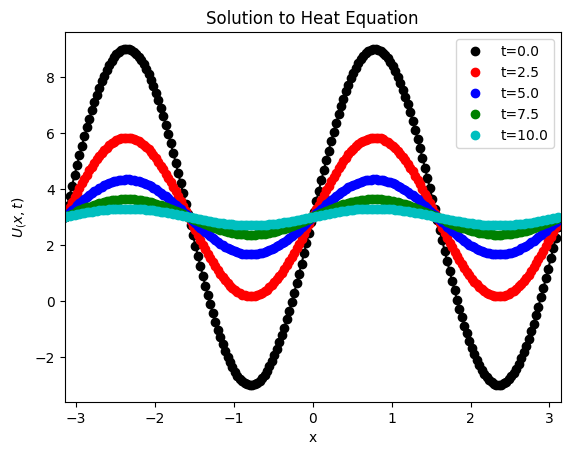

In [41]:
L = numpy.pi
kappa = 0.075
u_true = lambda x, t: 6.0 * numpy.sin(2.0 * numpy.pi / L * x) * numpy.exp(-4.0 * kappa * (numpy.pi / L)**2 * t) + 3.0

# Discretization and output times
# Note that there are m unknowns including one of the points either at 0 or L
m = 200
delta_x = (2.0 * L) / float(m + 1)
x = numpy.linspace(-L, L, m + 2)
x_fine = numpy.linspace(-L, L, 100)
output_times = (0.0, 2.5, 5.0, 7.5, 10.0)

# Solve
U = numpy.empty((len(output_times), m + 1))
U[0, :] = u_true(x[:-1], 0.0)
for (n, t) in enumerate(output_times[1:]):
    U[n + 1, :] = solve_heat_periodic_CN(m, kappa, L, output_times[n], t, U[n, :])

error = numpy.linalg.norm(delta_x * (U[-1, :] - u_true(x[:-1], output_times[-1])), ord=1)
print("Error = %s" % error)
assert error < 1e-3
print("Success!")

# Plot some of the results
colors = ['k', 'r', 'b', 'g', 'c']
fig = plt.figure()
axes = fig.add_subplot(1, 1, 1)
for (n, t) in enumerate(output_times):
    axes.plot(x_fine, u_true(x_fine, t), 'k-')
    axes.plot(x[:-1], U[n, :], "o%s" % colors[n], label='t=%s' % numpy.round(t, 4))
    axes.set_xlabel("x")
    axes.set_ylabel("$U_(x,t)$")
    axes.set_title("Solution to Heat Equation")
    axes.set_xlim([-L, L])
    axes.legend()
plt.show()

# Question 2 - Diffusion and Decay

Consider the partial differential equation 

$$
    \frac{\partial u}{\partial t} = \kappa \frac{\partial^2 u}{\partial x^2} -\gamma u,
$$

which models a diffusion with parameter $\kappa \in \mathbb R_{>0}$ with decay specified by $\gamma \in \mathbb R_{>0}$.

Consider a $\theta$-method of the form

$$
    U_j^{n+1} = U_j^n + \frac {\Delta t} {2\Delta x^2} \left( U_{j-1}^n - 2 U_j^n + U_{j+1}^n + U_{j-1}^{n+1} - 2U_j^{n+1}+U_{j+1}^{n+1} \right)-\Delta t\gamma\left( (1-\theta) U^n_j +\theta U_j^{n+1} \right)
$$

where $\theta$ is a parameter.

**(a)** [10] Assume $\kappa = 1 $, by computing the local truncation error, show that this method is $p$-th order accurate in time and second order accurate in space, where $p=2$ for $\theta = 0.5$ and $p=1$ otherwise.

**Answer:** Use 2 dimensional expansion to compute the local truncation error:

In space, we have

$$
    \begin{align}
    &U_{j+1}^n = U_j^n + (U_x)_j^n\Delta x + \dfrac{1}{2}(U_{xx})_j^n\Delta x^2 + \dfrac{1}{6}(U_{xxx})_j^n\Delta x^3 + \dfrac{1}{24}(U_{xxxx})_\xi^n\Delta x^4, \quad \xi\in[x_j, x_{j+1}]\\
    &U_{j-1}^n = U_j^n - (U_x)_j^n\Delta x + \dfrac{1}{2}(U_{xx})_j^n\Delta x^2 - \dfrac{1}{6}(U_{xxx})_j^n\Delta x^3 + \dfrac{1}{24}(U_{xxxx})_\xi^n\Delta x^4, \quad \xi\in[x_j, x_{j+1}]
    \end{align}
$$

Hence,

$$ 
    \begin{align}
    &U_{j-1}^n-2U_j^n+U_{j+1}^n=(U_{xx})_j^n\Delta x^2 + \dfrac{1}{12}(U_{xxxx})_\eta^n\Delta x^4, \quad \eta\in[x_j, x_{j+1}] \\
    &U_{j-1}^{n+1}-2U_j^{n+1}+U_{j+1}^{n+1}=(U_{xx})_j^{n+1}\Delta x^2 + \dfrac{1}{12}(U_{xxxx})_\eta^{n+1}\Delta x^4, \quad \eta\in[x_j, x_{j+1}]
    \end{align}
$$

Similarly, in time

$$
    U_j^{n+1} = U_j^n + (U_t)_j^n\Delta t + (U_tt)_\zeta^n\Delta t^2,\quad \zeta\in[t_j,t_{j+1}]
$$

Thus the original formula can be written as

$$
    \begin{align}
    &(U_t)_j^n + \dfrac{1}{2}(U_{tt})_j^{\zeta}\Delta t = \dfrac{1}{2}({\color{orange}(U_{xx})_j^n+(U_{xx})_j^{n+1}+O(\Delta x^2)})-\gamma(U_j^n+\theta (U_t)_j^n\Delta t + \theta (U_{tt})_j^{\zeta}\Delta t^2)\quad \Rightarrow\\
    &(U_t)_j^n + \dfrac{1}{2}(U_{tt})_j^{\zeta}\Delta t = (U_{xx})_j^n + \dfrac{1}{2}(U_{xxt})_j^{\zeta}\Delta t + O(\Delta x^2) -\gamma(U_j^n+\theta (U_t)_j^n\Delta t + \theta (U_{tt})_j^{\zeta}\Delta  t^2)\quad \Rightarrow\\
    &(U_t)_j^n - (U_{xx})_j^n + \gamma U_j^n = \dfrac{1}{2}([-U_{t}+U_{xx}-2\gamma\theta U]_t)_j^{\zeta}{\color{skyblue}{\Delta t}} + {\color{orange}O(\Delta x^2)} -\underbrace{\gamma\theta (U_{tt})_j^{\zeta}{\color{green}\Delta  t^2}}_{=O(\Delta t^2)}
    \end{align}
$$

Note that the right hand side depicts the error, and 

1. when $\theta=\dfrac{1}{2}$, $-U_{t}+U_{xx}-2\gamma\theta U$ vanishes and cancelled the only term containing $\Delta t$ of order $1$, the left term is of order $2$.
2. when $\theta\neq\dfrac{1}{2}$ $-U_{t}+U_{xx}-2\gamma\theta U\not\equiv 0$, the term containing $\Delta t$ of order $1$ still exists.
3. the term $O(\Delta x^2)$, which comes from the terms colored orange never vanishes.

Thus this method is $p$-th order accurate in time and second order accurate in space, where $p=2$ for $\theta = \dfrac{1}{2}$ and $p=1$ otherwise.



**(b)** [10] Using von Neumann analysis, show that this method is unconditionally stable if $\theta \geq 0.5$.

**Answer:** Plug $U^n_j = e^{ij\Delta x \xi}$ in, we have

$$
    U^{n+1}_j = U^n_j + \frac{\Delta t}{2 \Delta x^2} \left[ \left(e^{i \Delta x \xi} - 2 + e^{-i\Delta x \xi} \right) U^n_{j}+ \left(e^{i \Delta x \xi} - 2 + e^{-i\Delta x \xi} \right) U^{n+1}_{j} \right ]-\Delta t\gamma\left( (1-\theta) U_j +\theta U_j^{n+1} \right)
$$

then let $U^{n+1}_j = g(\xi) U^n_j$, we have

$$
    \begin{align}
    g = 1 + \frac{\Delta t}{2 \Delta x^2} \left(  e^{i \Delta x \xi} - 2 + e^{-i\Delta x \xi} \right ) (1 + g)-\Delta t\gamma\left( (1-\theta)+\theta g \right)
    \end{align}
$$

from which we can derive that 

$$
    g = \frac{1+ z -\Delta t \gamma (1-\theta)}{1 - z + \Delta t \gamma \theta}
$$

where 

$$
z = \dfrac{\Delta t}{\Delta x^2} \left (e^{i \Delta x \xi} - 2 + e^{-i\Delta x \xi} \right ) = \dfrac{2 \Delta t}{\Delta x^2} (\cos(\xi \Delta x) - 1)
$$

when $\theta\geqslant 0.5$, as long as $\Delta t\geqslant \dfrac{2z}{\gamma}$, we'd have

$$
    -1\leqslant\frac{1+ z -\Delta t \gamma (1-\theta)}{1 - z + \Delta t \gamma \theta} \leqslant 1 
$$

Therefore this method is unconditionally stable.


**(c)** [10] Show that, if $\theta = 0$, then the method  is stable provided $\Delta t \leq \frac 2 \gamma$, independent of $\Delta x$.

By the last subquestion, we know if $\theta=0$, then

$$
    g = \frac{1+ z -\Delta t \gamma}{1 - z}
$$

Thus the method is stable iff

$$
    g\in[-1,1]\Leftrightarrow \Delta t\in[0, \dfrac{2}{\gamma}]
$$

## Question 3 - Heat Equation

Consider the heat equation with zero boundary conditions:

$$
    \frac{\partial u}{\partial t} = \kappa \frac{\partial^2 u}{\partial x^2} \qquad \text{ on } [0,L]\times \mathbb R_+\\
    u(x,0) = u_0(x) ~~~~~~ u(0,t) = 0 ~~~~~ u(L,t) = 0.
$$

**(a)** [20] Implement the *backward Euler* and *Crank-Nicholson* methods to solve this equation.  You are responsible for picking a $\Delta t$ so that the numerical method has enough accuracy but hits the end time $t_f$ exactly (or as much as this is possible with floating point arithmetic).  Note that making $\Delta t$ too small may harm your accuracy as much as picking one that is too big.

Discretization formula for backward Euler:

$$
    \dfrac{T_i^{n+1} - T_i^n}{\Delta t} = \kappa\dfrac{T_{i+1}^{n+1} - 2T_i^{n+1} + T_{i-1}^{n+1}}{\Delta x^2}
$$

After moving terms:

$$
    (1+2\sigma)T_i^{n+1} - \sigma T_{i+1}^{n+1} - \sigma T_{i-1}^{n+1} = T_i^n,\quad \sigma=\dfrac{\kappa \Delta t}{\Delta x^2}
$$

In [29]:
def solve_heat_BE(m, kappa, L, t_0, t_final, U_0, g_0, g_1):
    """Solve the heat equation using backward Euler and given boundaries
    
    Function will take the necessary number of time steps to reach t_final
    from t_0.  Note that this may mean taking a slightly smaller time step 
    size to hit t_f exactly.
    
    :Input:
     - *m* (int) Number of points use to discretize the domain.  Note that
       the total number of points is *m+2*, which includes the boundaries.
     - *kappa* (float) Diffusion coefficient
     - *L* (float) Length of the domain
     - *t_0* (float) Starting time
     - *t_final* (float) Time to integrate to
     - *U_0* (numpy.ndarray) Initial condition at time t_0, should be m+2
     - *g_0* (func) Boundary condition at x=0
     - *g_1* (func) Boundary condition at x=L
     
    :Output:
     - (numpy.ndarray) Solution at time t_final.  Note that this vector should m+2
       and include the boundary conditions.
    """

    delta_x = L / float(m + 1)
    x = numpy.linspace(0.0, L, m + 2)

    delta_t = delta_x * delta_x / kappa * 0.5
    Nt = math.ceil((t_final - t_0) / delta_t)
    delta_t = (t_final - t_0) / Nt

    sigma = kappa * delta_t / (delta_x * delta_x)

    main_diag = numpy.array([1 + 2 * sigma] * (m + 2))
    sub_diag = numpy.array([-sigma] * (m + 2))

    L = sparse.spdiags([sub_diag, main_diag, sub_diag], [-1, 0, 1], m + 2, m + 2).tocsr()
    L[0, 1] = L[-1, -2] = 0.0
    U = U_0.copy()

    for i in range(Nt):
       U_temp = U.copy()
       U_temp[0] = (1 + 2 * sigma) * g_0(t_0 + (i + 1) * delta_t)
       U_temp[-1] = (1 + 2 * sigma) * g_1(t_0 + (i + 1) * delta_t)
       U_temp = linalg.spsolve(L, U_temp)
       U = U_temp
    
    return U

Error BE = 8.158707071881708e-05


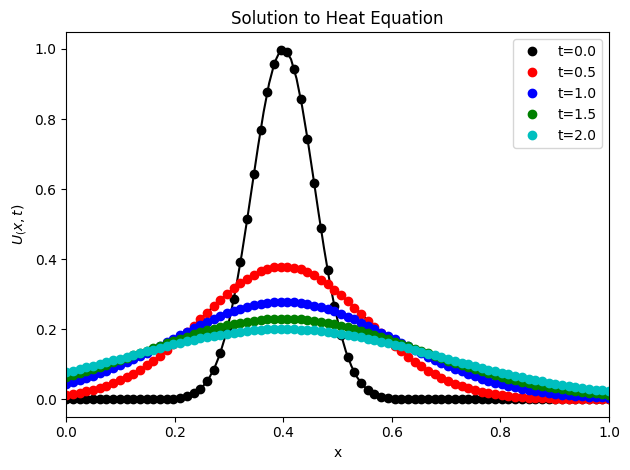

In [31]:
beta = 150.0
kappa = 0.02
L = 1.0
u_true = lambda x, t: numpy.exp(-(x - 0.4)**2. / (4.0 * kappa * t + 1.0 / beta)) \
                                            / numpy.sqrt(4.0 * kappa * beta * t + 1.0)

# Note that these will not be precisely zero
g_0 = lambda t: u_true(0.0, t)
g_1 = lambda t: u_true(L, t)

# Discretization and output times
m = 80
x = numpy.linspace(0.0, L, m + 2)
x_fine = numpy.linspace(0.0, L, 100)
delta_x = L / float(m + 1)
output_times = (0.0, 0.5, 1.0, 1.5, 2.0)

# Solve
U_BE = numpy.empty((len(output_times), m + 2))
U_BE[0, :] = u_true(x, 0.0)
for (n, t) in enumerate(output_times[1:]):
    U_BE[n + 1, :] = solve_heat_BE(m, kappa, L, output_times[n], t, U_BE[n, :], g_0, g_1)

error = numpy.linalg.norm(delta_x * (U_BE[-1, :] - u_true(x, output_times[-1])), ord=1)
print("Error BE = %s" % error)
assert error < 1e-3

# Plot some of the results
colors = ['k', 'r', 'b', 'g', 'c']
fig = plt.figure()
axes_BE = fig.add_subplot(1, 1, 1)
for (n, t) in enumerate(output_times):
    axes_BE.plot(x_fine, u_true(x_fine, t), 'k-')
    axes_BE.plot(x, U_BE[n, :], "o%s" % colors[n], label='t=%s' % numpy.round(t, 4))
    axes_BE.set_xlabel("x")
    axes_BE.set_ylabel("$U_(x,t)$")
    axes_BE.set_title("Solution to Heat Equation")
    axes_BE.set_xlim([0, L])
    axes_BE.legend()
    
plt.tight_layout()
plt.show()

In [32]:
def solve_heat_CN(m, kappa, L, t_0, t_final, U_0, g_0, g_1):
    """Solve the heat equation using Crank-Nicholson and given boundaries
    
    Function will take the necessary number of time steps to reach t_final
    from t_0.  Note that this may mean taking a slightly smaller time step 
    size to hit t_f exactly.
    
    :Input:
     - *m* (int) Number of points use to discretize the domain.  Note that
       the total number of points is *m+2*, which includes the boundaries.
     - *kappa* (float) Diffusion coefficient
     - *L* (float) Length of the domain
     - *t_0* (float) Starting time
     - *t_final* (float) Time to integrate to
     - *U_0* (numpy.ndarray) Initial condition at time t_0, should be m+2
     - *g_0* (func) Boundary condition at x=0
     - *g_1* (func) Boundary condition at x=L
     
    :Output:
     - (numpy.ndarray) Solution at time t_final.  Note that this vector should m+2
       and include the boundary conditions.
    """

    delta_x = L / float(m + 1)
    x = numpy.linspace(0.0, L, m + 2)

    delta_t = delta_x * delta_x / kappa * 0.5
    Nt = math.ceil((t_final - t_0) / delta_t)
    delta_t = (t_final - t_0) / Nt

    sigma = kappa * delta_t / (delta_x * delta_x)

    main_diag_1 = numpy.array([2 * (1 + sigma)] * (m + 2))
    main_diag_2 = numpy.array([2 * (1 - sigma)] * (m + 2))
    sub_diag = numpy.array([sigma] * (m + 2))

    L = sparse.spdiags([-sub_diag, main_diag_1, -sub_diag], [-1, 0, 1], m + 2, m + 2).tocsr()
    R = sparse.spdiags([sub_diag, main_diag_2, sub_diag], [-1, 0, 1], m + 2, m + 2).tocsr()
    L[0, 1] = L[-1, -2] = R[0, 1] = R[-1, -2] = 0.0
    U = U_0.copy()

    for i in range(Nt):
       U_temp = R @ U
       U_temp[0] = 2 * (1 + sigma) * g_0(t_0 + (i + 1) * delta_t)
       U_temp[-1] = 2 * (1 + sigma) * g_1(t_0 + (i + 1) * delta_t)
       U_temp = linalg.spsolve(L, U_temp)
       U = U_temp
    
    return U

Error CN = 0.000298132151016124
Success!


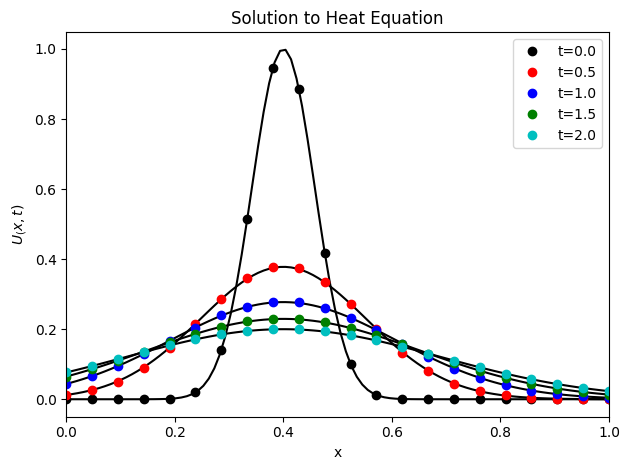

In [18]:
beta = 150.0
kappa = 0.02
L = 1.0
u_true = lambda x, t: numpy.exp(-(x - 0.4)**2. / (4.0 * kappa * t + 1.0 / beta)) \
                                            / numpy.sqrt(4.0 * kappa * beta * t + 1.0)

# Note that these will not be precisely zero
g_0 = lambda t: u_true(0.0, t)
g_1 = lambda t: u_true(L, t)

# Discretization and output times
m = 20
x = numpy.linspace(0.0, L, m + 2)
x_fine = numpy.linspace(0.0, L, 100)
delta_x = L / float(m + 1)
output_times = (0.0, 0.5, 1.0, 1.5, 2.0)

# Solve
U_CN = numpy.empty((len(output_times), m + 2))
U_CN[0, :] = u_true(x, 0.0)
for (n, t) in enumerate(output_times[1:]):
    U_CN[n + 1, :] = solve_heat_CN(m, kappa, L, output_times[n], t, U_CN[n, :], g_0, g_1)

error = numpy.linalg.norm(delta_x * (U_CN[-1, :] - u_true(x, output_times[-1])), ord=1)
print(("Error CN = %s" % error))
assert error < 1e-3
print("Success!")

# Plot some of the results
colors = ['k', 'r', 'b', 'g', 'c']
fig = plt.figure()
axes_CN = fig.add_subplot(1, 1, 1)
for (n, t) in enumerate(output_times):
    axes_CN.plot(x_fine, u_true(x_fine, t), 'k-')
    axes_CN.plot(x, U_CN[n, :], "o%s" % colors[n], label='t=%s' % numpy.round(t, 4))
    axes_CN.set_xlabel("x")
    axes_CN.set_ylabel("$U_(x,t)$")
    axes_CN.set_title("Solution to Heat Equation")
    axes_CN.set_xlim([0, L])
    axes_CN.legend()

plt.tight_layout()
plt.show()

**(b)** [5] Perform a convergence analysis on the methods above (i.e. plot their convergence).

In [42]:
beta = 150.0
kappa = 0.02
L = 1.0
u_true = lambda x, t: numpy.exp(-(x - 0.4)**2. / (4.0 * kappa * t + 1.0 / beta)) \
                                            / numpy.sqrt(4.0 * kappa * beta * t + 1.0)

# Note that these will not be precisely zero
g_0 = lambda t: u_true(0.0, t)
g_1 = lambda t: u_true(L, t)

# Discretization and output times
ms = [20, 40, 80, 160, 320, 640, 1280]
errors = [0] * len(ms)
for (i, m) in enumerate(ms):
    x = numpy.linspace(0.0, L, m + 2)
    x_fine = numpy.linspace(0.0, L, 100)
    delta_x = L / float(m + 1)
    output_times = (0.0, 0.5, 1.0, 1.5, 2.0)

    # Solve
    U_BE = numpy.empty((len(output_times), m + 2))
    U_BE[0, :] = u_true(x, 0.0)
    for (n, t) in enumerate(output_times[1:]):
        U_BE[n + 1, :] = solve_heat_BE(m, kappa, L, output_times[n], t, U_BE[n, :], g_0, g_1)

    errors[i] = numpy.linalg.norm(delta_x * (U_BE[-1, :] - u_true(x, output_times[-1])), ord=1)

7it [00:41,  5.90s/it]


Text(0.5, 1.0, 'Error w.r.t m - Backward Euler')

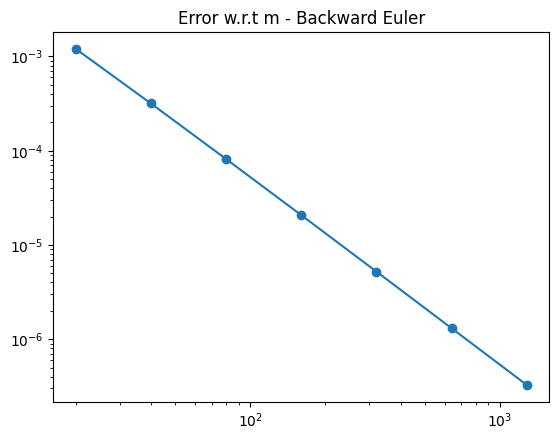

In [45]:
plt.loglog(ms, errors)
plt.scatter(ms, errors)
plt.title("Error w.r.t m - Backward Euler")

From the graph we can see that the backward euler converges as the discretization becomes denser.

In [46]:
beta = 150.0
kappa = 0.02
L = 1.0
u_true = lambda x, t: numpy.exp(-(x - 0.4)**2. / (4.0 * kappa * t + 1.0 / beta)) \
                                            / numpy.sqrt(4.0 * kappa * beta * t + 1.0)

# Note that these will not be precisely zero
g_0 = lambda t: u_true(0.0, t)
g_1 = lambda t: u_true(L, t)

# Discretization and output times
ms = [20, 40, 80, 160, 320, 640, 1280]
errors = [0] * len(ms)
for (i, m) in enumerate(ms):
    x = numpy.linspace(0.0, L, m + 2)
    x_fine = numpy.linspace(0.0, L, 100)
    delta_x = L / float(m + 1)
    output_times = (0.0, 0.5, 1.0, 1.5, 2.0)

    # Solve
    U_CN = numpy.empty((len(output_times), m + 2))
    U_CN[0, :] = u_true(x, 0.0)
    for (n, t) in enumerate(output_times[1:]):
        U_CN[n + 1, :] = solve_heat_CN(m, kappa, L, output_times[n], t, U_CN[n, :], g_0, g_1)

    errors[i] = numpy.linalg.norm(delta_x * (U_CN[-1, :] - u_true(x, output_times[-1])), ord=1)

Text(0.5, 1.0, 'Error w.r.t m - Crank-Nicholson')

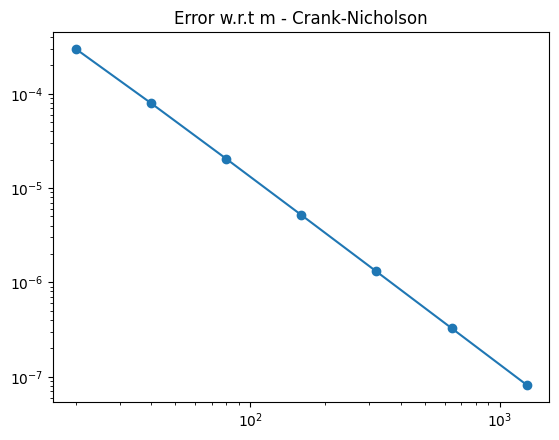

In [47]:
plt.loglog(ms, errors)
plt.scatter(ms, errors)
plt.title("Error w.r.t m - Crank-Nicholson")

From the graph we can see that the Crank-Nicholson method converges as the discretization becomes denser as well.

**(c)** [10] Are there initial and/or boundary conditions that you would expect would not be well handled in the methods above?  Justify your solution with the appropriate analysis and numerical experiment.

For initial distribution with discontinuities and sudden changed, the method will not handle it well. Since the two methods are both based on discretization, sudden change will create unstablity or nan values.

For example let $u_0(x)=\sin\dfrac{1}{x-1/2}$, which oscillate at $x=1/2$ and see what will happen.

In [62]:
beta = 150.0
kappa = 0.02
L = 1.0

# Note that these will not be precisely zero
g_0 = lambda t: 0
g_1 = lambda t: 0

m = 20
x = numpy.linspace(0.0, L, m + 2)
delta_x = L / float(m + 1)

U_CN = numpy.divide(1, x - L / 2)

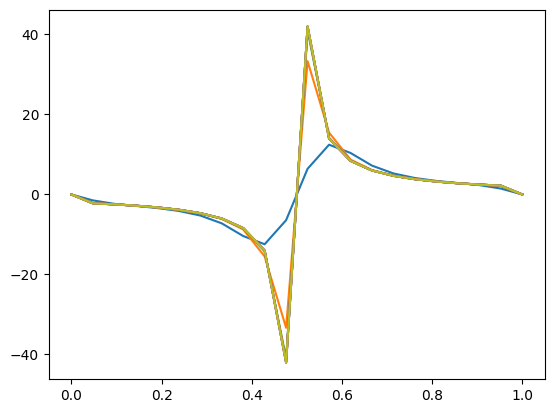

In [64]:
for i in range(1, 10):
    sol = solve_heat_CN(m, kappa, L, 0, 10 ** -i, U_CN, g_0, g_1)
    plt.plot(x, sol)

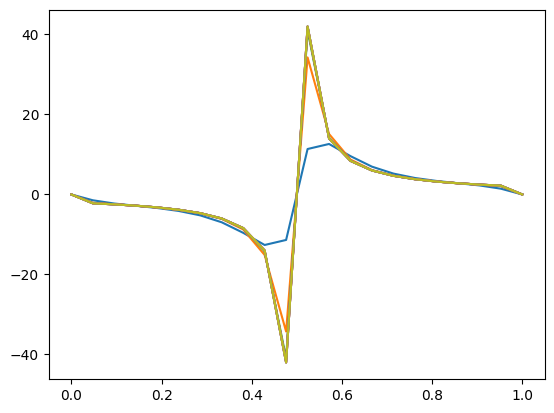

In [65]:
for i in range(1, 10):
    sol = solve_heat_BE(m, kappa, L, 0, 10 ** -i, U_CN, g_0, g_1)
    plt.plot(x, sol)

Theoretically, for such initial value, when $\Delta x$ is taken smaller and smaller, the graph should tend to the initial heat distribution, but as we can see, for the 2 given method, such initial values are not handled right.